<a href="https://colab.research.google.com/github/Syeda-Maham-fatima05/Intelligent-Vacuum-Cleaning-Robot/blob/main/Student1_Environment_GBFS/Student1_Environment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import ast
import heapq
import itertools
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from collections import deque

In [2]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded.keys()))

print("Uploaded file:", filename)

Saving Environment.txt to Environment.txt
Uploaded file: Environment.txt


In [3]:
def parse_coordinates(text):
    coordinates = ast.literal_eval(text.strip())

    # Convert a single coordinate into a list
    if (
        isinstance(coordinates, tuple)
        and len(coordinates) == 2
        and all(isinstance(x, int) for x in coordinates)
    ):
        coordinates = [coordinates]

    return [tuple(point) for point in coordinates]


def load_environment(filename):

    with open(filename, "r") as file:
        lines = [line.strip() for line in file if line.strip()]

    # Read grid dimensions
    rows, cols = map(int, lines[0].split(","))

    # Read obstacle information
    obstacle_count = int(lines[1])
    obstacles = set(parse_coordinates(lines[2]))

    # Read dirty location information
    dirty_count = int(lines[3])
    dirty_locations = parse_coordinates(lines[4])

    # Read charging station
    charging_station = parse_coordinates(lines[5])[0]

    grid = {
        "rows": rows,
        "cols": cols,
        "obstacles": obstacles,
        "dirty_locations": dirty_locations,
        "charging_station": charging_station
    }

    return grid

In [23]:
grid = load_environment(filename)

print("Grid Size:", grid["rows"], "x", grid["cols"])
print("Obstacles:", grid["obstacles"])
print("Dirty Locations:", grid["dirty_locations"])
print("Charging Station:", grid["charging_station"])

Grid Size: 8 x 8
Obstacles: {(2, 4), (6, 5), (0, 0), (6, 1), (7, 3), (0, 5), (3, 6), (3, 2)}
Dirty Locations: [(5, 3), (4, 4), (1, 2), (6, 7)]
Charging Station: (0, 7)


In [4]:
def validate_environment(grid):

    rows = grid["rows"]
    cols = grid["cols"]
    obstacles = grid["obstacles"]
    dirty = grid["dirty_locations"]
    charging = grid["charging_station"]

    errors = []

    # Check grid dimensions
    if rows < 8 or cols < 8:
        errors.append("Grid must be at least 8x8.")

    # Check obstacle count
    if len(obstacles) < 6:
        errors.append("At least 6 obstacles are required.")

    # Check dirty locations
    if len(dirty) < 4:
        errors.append("At least 4 dirty locations are required.")

    # Check duplicate coordinates
    if len(dirty) != len(set(dirty)):
        errors.append("Duplicate dirty locations found.")

    # Check coordinate boundaries
    all_positions = obstacles | set(dirty) | {charging}

    for r, c in all_positions:
        if not (0 <= r < rows and 0 <= c < cols):
            errors.append(f"Coordinate {(r, c)} is outside the grid.")

    # Check overlapping positions
    if obstacles.intersection(dirty):
        errors.append("An obstacle overlaps a dirty location.")

    if charging in obstacles:
        errors.append("Charging station overlaps an obstacle.")

    if charging in dirty:
        errors.append("Charging station overlaps a dirty location.")

    # Check every dirty location is reachable
    for location in dirty:
        if not is_reachable(charging, location, grid):
            errors.append(f"Dirty location {location} is unreachable.")

    if errors:
        print("Environment is INVALID:")
        for error in errors:
            print("-", error)
        return False

    print("Environment is VALID!")
    return True

In [5]:
def is_reachable(start, goal, grid):

    queue = deque([start])
    visited = {start}

    while queue:

        current = queue.popleft()

        if current == goal:
            return True

        for next_state, action, cost in get_successors(current, grid):

            if next_state not in visited:
                visited.add(next_state)
                queue.append(next_state)

    return False

In [11]:
grid = load_environment(filename)

print("Grid Size:", grid["rows"], "x", grid["cols"])
print("Obstacles:", grid["obstacles"])
print("Dirty Locations:", grid["dirty_locations"])
print("Charging Station:", grid["charging_station"])

Grid Size: 8 x 8
Obstacles: {(2, 4), (6, 5), (0, 0), (6, 1), (7, 3), (0, 5), (3, 6), (3, 2)}
Dirty Locations: [(5, 3), (4, 4), (1, 2), (6, 7)]
Charging Station: (0, 7)


In [24]:
def display_grid(grid):

    rows = grid["rows"]
    cols = grid["cols"]

    fig, ax = plt.subplots(figsize=(8, 8))

    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)

    # Draw grid cells
    for r in range(rows):
        for c in range(cols):

            color = "white"
            label = ""

            if (r, c) in grid["obstacles"]:
                color = "gray"
                label = "X"

            elif (r, c) in grid["dirty_locations"]:
                color = "orange"
                index = grid["dirty_locations"].index((r, c))
                label = f"D{index + 1}"

            elif (r, c) == grid["charging_station"]:
                color = "lightgreen"
                label = "C"

            rect = plt.Rectangle(
                (c, r), 1, 1,
                facecolor=color,
                edgecolor="black"
            )

            ax.add_patch(rect)

            ax.text(
                c + 0.5,
                r + 0.5,
                label,
                ha="center",
                va="center",
                fontsize=12,
                fontweight="bold"
            )

    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_xticklabels(range(cols))
    ax.set_yticklabels(range(rows))

    ax.set_title("Vacuum Cleaning Robot Environment")
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")

    plt.grid(False)
    plt.show()

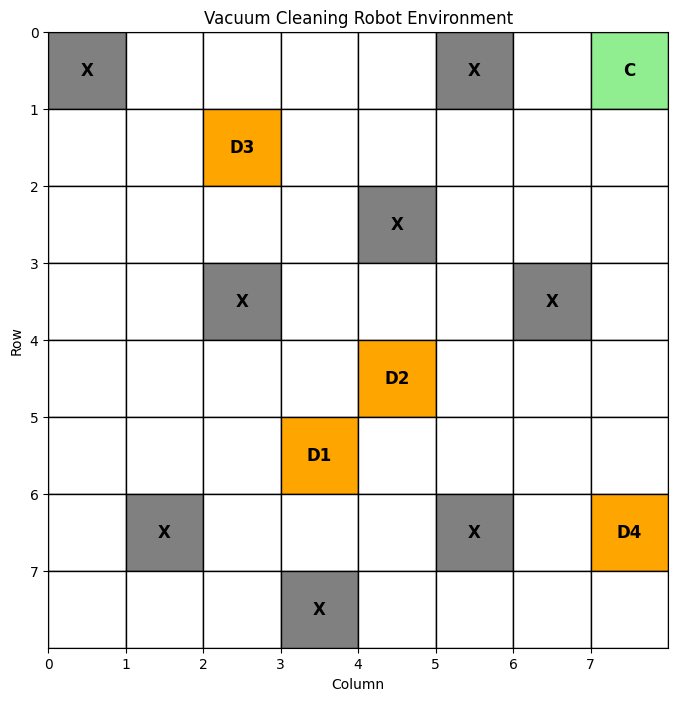

In [25]:
display_grid(grid)

In [26]:
def get_successors(state, grid):

    row, col = state

    moves = [
        (-1, 0, "UP"),
        (1, 0, "DOWN"),
        (0, -1, "LEFT"),
        (0, 1, "RIGHT")
    ]

    successors = []

    for dr, dc, action in moves:

        new_row = row + dr
        new_col = col + dc

        next_state = (new_row, new_col)

        # Check grid boundaries and obstacles
        if (
            0 <= new_row < grid["rows"]
            and 0 <= new_col < grid["cols"]
            and next_state not in grid["obstacles"]
        ):

            successors.append((next_state, action, 1))

    return successors

In [27]:
environment_valid = validate_environment(grid)

Environment is VALID!


In [18]:
def goal_test(state, goal_state):

    return state == goal_state

In [19]:
def path_cost(path):

    if not path:
        return 0

    return len(path) - 1

In [20]:
example_path = [(0, 7), (1, 7), (1, 6), (2, 6)]

print("Path Cost:", path_cost(example_path))

Path Cost: 3


In [21]:
def heuristic(state, goal_state):

    row1, col1 = state
    row2, col2 = goal_state

    return abs(row1 - row2) + abs(col1 - col2)

In [22]:
print(heuristic((0, 7), (5, 3)))

9
